In [38]:
from IPython.display import display, HTML
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif
from sklearn.feature_extraction import DictVectorizer

from sklearn.metrics import mutual_info_score, roc_auc_score, roc_curve, accuracy_score, recall_score, precision_score, confusion_matrix


### Loading the dataset


In [2]:
df = pd.read_csv('./data/heart.csv')
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


### EDA

In [3]:
display(df.shape)
display(HTML("<hr>"))

df.info()

(918, 12)

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 86.2 KB


In [4]:
display(df.describe())
display(HTML("<hr>"))

print (df.isnull().sum())
display(HTML("<hr>"))

display(df.duplicated().sum())
display(HTML("<hr>"))

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64


np.int64(0)

In [5]:
df.columns

Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease'],
      dtype='str')

In [6]:
df.columns = (
    df.columns
    .str.replace(r'(?<=[a-z])(?=[A-Z])', '_', regex=True) 
    .str.lower() 
)
df.columns

Index(['age', 'sex', 'chest_pain_type', 'resting_bp', 'cholesterol',
       'fasting_bs', 'resting_ecg', 'max_hr', 'exercise_angina', 'oldpeak',
       'st_slope', 'heart_disease'],
      dtype='str')

heart_disease
1    508
0    410
Name: count, dtype: int64
heart_disease
1    0.55
0    0.45
Name: proportion, dtype: float64


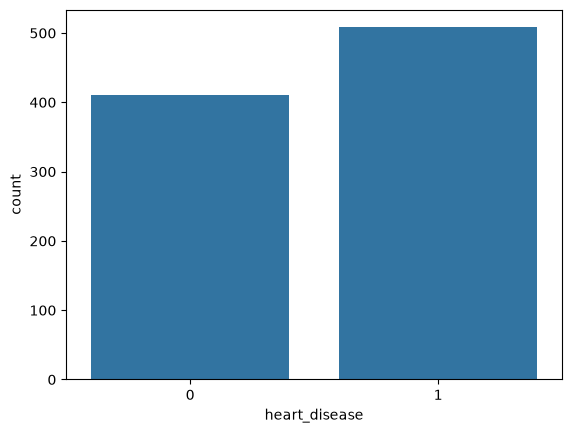

In [7]:
print(df["heart_disease"].value_counts())
print(df["heart_disease"].value_counts(normalize=True).round(2))
sns.countplot(x="heart_disease", data=df); plt.show()

About 55% of patients have heart disease and 45% don’t, so the classes are fairly balanced. Accuracy is a fair metric, but I’ll report AUC and recall too.



In [8]:
(df[["resting_bp", "cholesterol"]] == 0).sum()

resting_bp       1
cholesterol    172
dtype: int64

172 cholesterol values and 1 resting BP value are 0, which isn't physically possible, so they're hidden missing values. I'll convert them to NaN and fill with the median, fitted on the training set only

In [9]:
cols = ["resting_bp", "cholesterol"]
df[cols] = df[cols].replace(0, np.nan)

(df[cols] == 0).sum()

resting_bp     0
cholesterol    0
dtype: int64

In [10]:
df[cols].isna().sum()

resting_bp       1
cholesterol    172
dtype: int64

In [11]:
numerical_col = df.select_dtypes(include='number').columns.tolist()
numerical_col.remove('heart_disease')
categorical_col = df.select_dtypes(exclude='number').columns.tolist()

numerical_col.remove('fasting_bs')
categorical_col.append('fasting_bs')
print(numerical_col, "\n", categorical_col)

['age', 'resting_bp', 'cholesterol', 'max_hr', 'oldpeak'] 
 ['sex', 'chest_pain_type', 'resting_ecg', 'exercise_angina', 'st_slope', 'fasting_bs']


#### Numerical features analysis

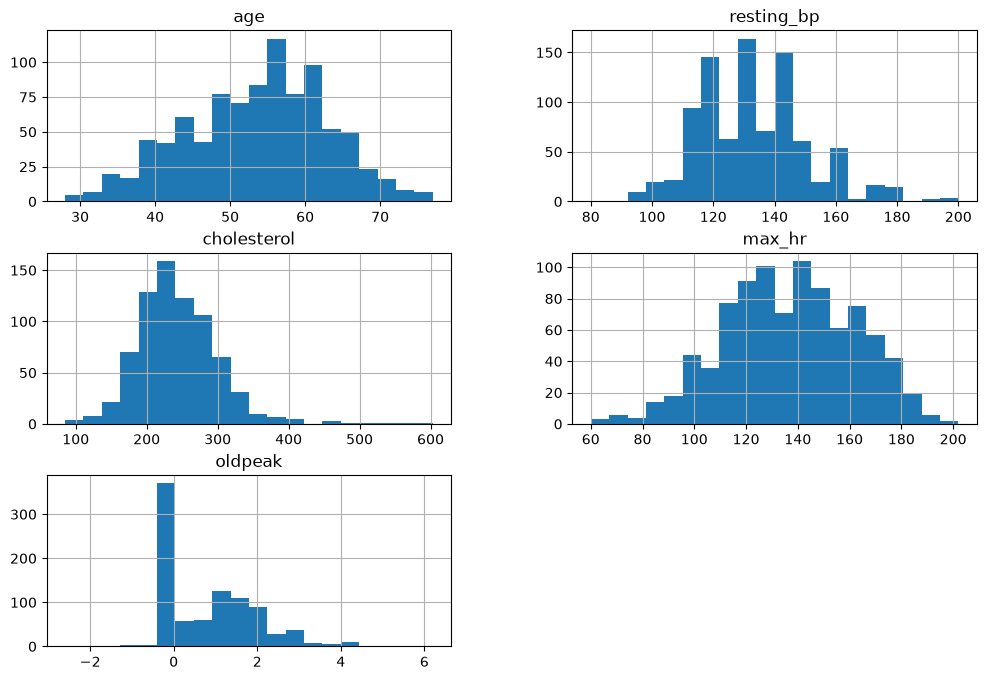

                 age  resting_bp  cholesterol  max_hr  oldpeak
heart_disease                                                 
0              50.55      130.18       238.77  148.15     0.41
1              55.90      134.45       251.06  127.66     1.27


In [12]:
df[numerical_col].hist(bins=20, figsize=(12, 8))
plt.show()

print(df.groupby("heart_disease")[numerical_col].mean().round(2))

- Disease group: lower max heart rate (127.66 vs 148.15), higher oldpeak (1.27 vs 0.41), older (around 56 vs around 51).
- Resting BP and cholesterol differ only slightly.
- Cholesterol and oldpeak are right-skewed.

Patients with heart disease tend to be older and have higher resting blood pressure and cholesterol levels on average. However, these differences are relatively small.

max_hr is noticeably lower, while oldpeak is higher among patients with heart disease. These features may be useful for predicting heart disease.

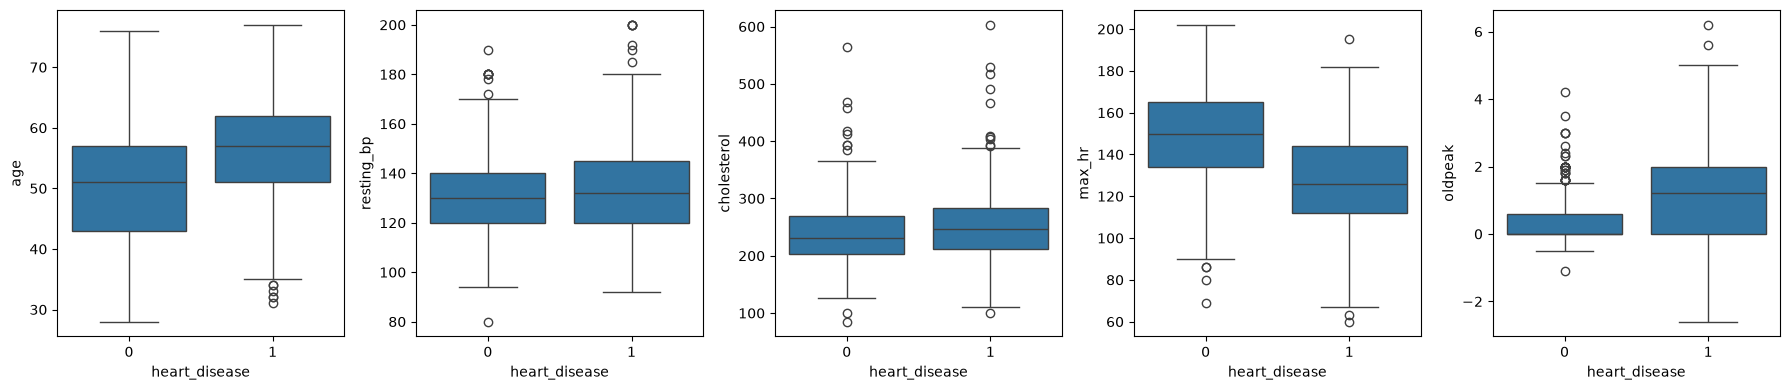

In [13]:

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, c in zip(axes, numerical_col):
    sns.boxplot(x="heart_disease", y=c, data=df, ax=ax)
plt.tight_layout()
plt.show()

The boxplots reveal some potential outliers.
- Max heart rate and oldpeak separate the classes best.
- Resting BP and cholesterol overlap heavily.
- Outliers in cholesterol, resting BP and oldpeak, a few negative oldpeak values.

#### Categorical features analysis

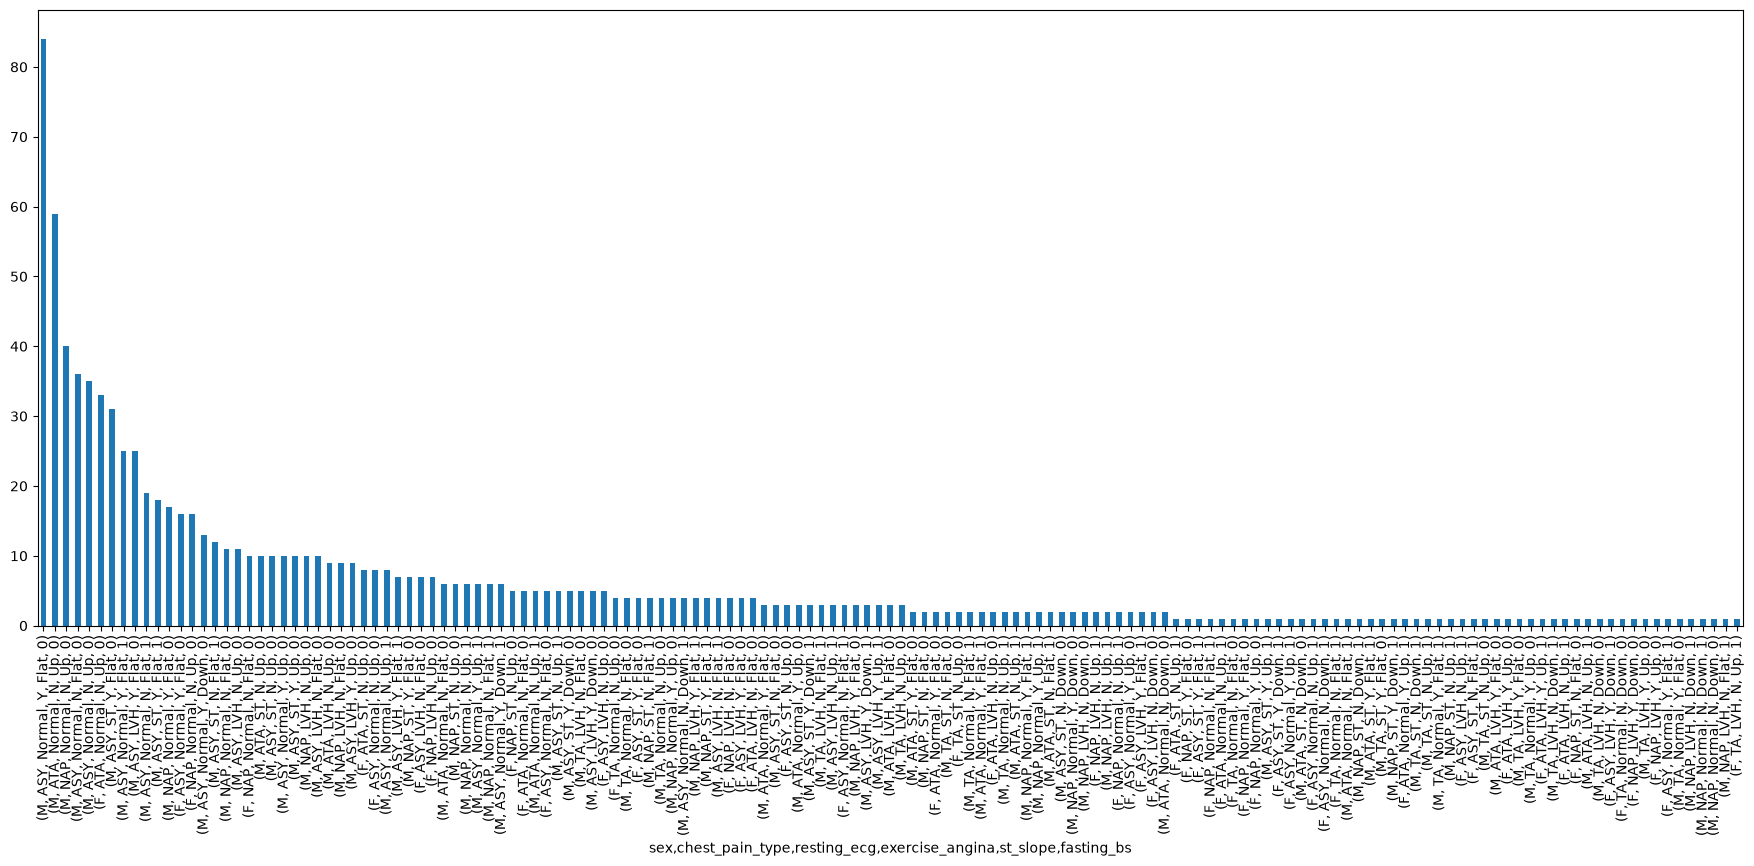

In [14]:
df[categorical_col].value_counts().plot(kind="bar", figsize=(22, 8))
plt.show()

In [15]:
for col in categorical_col:
    print(f"\n{col}")
    display(pd.crosstab(
        df[col],
        df['heart_disease'],
        normalize='index'
    ).round(3))
    print("--------------------------")


sex


heart_disease,0,1
sex,,
F,0.741,0.259
M,0.368,0.632


--------------------------

chest_pain_type


heart_disease,0,1
chest_pain_type,,
ASY,0.210,0.790
ATA,0.861,0.139
NAP,0.645,0.355
TA,0.565,0.435


--------------------------

resting_ecg


heart_disease,0,1
resting_ecg,,
LVH,0.436,0.564
Normal,0.484,0.516
ST,0.343,0.657


... (3 outputs left out)

heart_disease,0,1
st_slope,,
Down,0.222,0.778
Flat,0.172,0.828
Up,0.803,0.197


--------------------------

fasting_bs


heart_disease,0,1
fasting_bs,,
0,0.520,0.480
1,0.206,0.794


--------------------------



- Exercise angina: 85% disease vs 35% without.
- Chest pain ASY: 79% vs 14% for ATA.
- ST slope Up: 20%; Flat and Down: about 80%.

- Fasting blood sugar = 1: 79% vs 48%.
- Men 63% vs women 26%, but only about 21% of patients are women. Which is an imbalance.
- Resting ECG differs little.


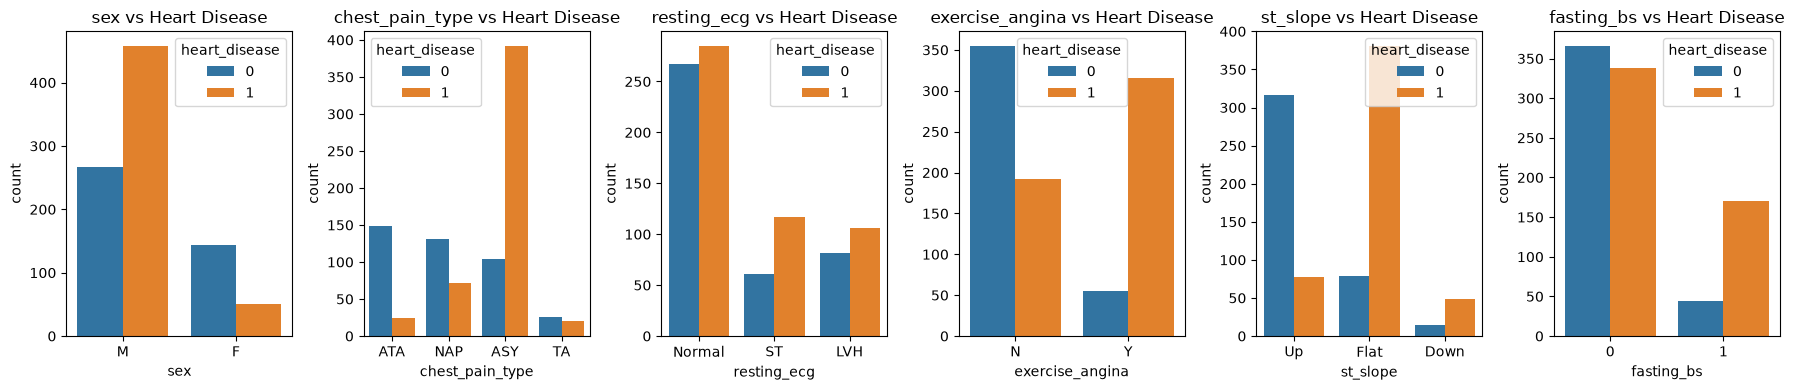

In [16]:
fig, axes = plt.subplots(1, 6, figsize=(18, 4))

for col, ax in zip(categorical_col, axes.flatten()):
    sns.countplot(
        data=df,
        x=col,
        hue='heart_disease',
        ax=ax
    )
    ax.set_title(f'{col} vs Heart Disease')

plt.tight_layout()
plt.show()

ChestPainType, ExerciseAngina, and ST_Slope show the strongest differences in heart disease proportions across categories. Sex and FastingBS also show noticeable differences, while RestingECG shows relatively smaller differences.

These features may be useful for predicting heart disease.

#### Correlations

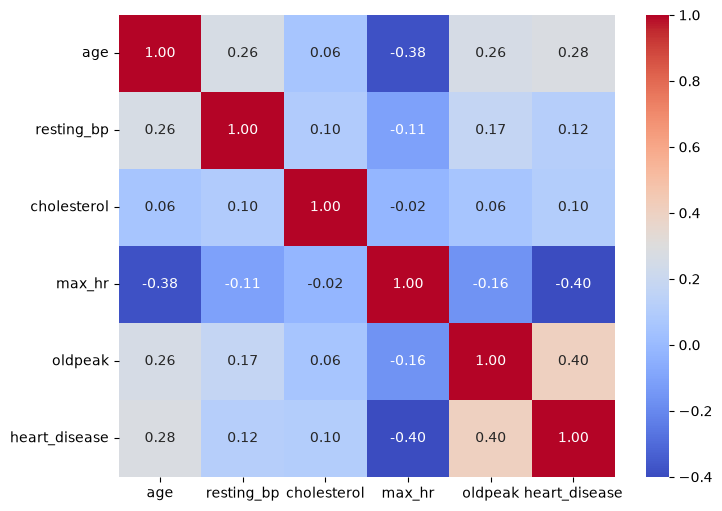

In [17]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[numerical_col + ["heart_disease"]].corr(),
            annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

- Strongest links with heart disease: max_hr (-0.40), oldpeak (0.40), age (0.28).
- Weak: resting_bp (0.12) and cholesterol (0.10).

#### Feature importance


In [19]:
def mutual_info_heart_disease_score(series):
    return mutual_info_score(series, df.heart_disease)

mi = df[categorical_col].apply(mutual_info_heart_disease_score)
mi.sort_values(ascending=False)

st_slope           0.207474
chest_pain_type    0.155988
exercise_angina    0.131680
sex                0.047477
fasting_bs         0.038040
resting_ecg        0.006045
dtype: float64

st_slope (0.207), chest_pain_type (0.156) and exercise_angina (0.132) are the most informative categorical features, resting_ecg (0.006) is the least.

st_slope_Up            0.227
st_slope_Flat          0.175
exercise_angina_Y      0.128
oldpeak                0.125
max_hr                 0.079
chest_pain_type_ATA    0.069
cholesterol            0.065
age                    0.047
sex_M                  0.047
fasting_bs             0.036
chest_pain_type_TA     0.018
resting_bp             0.012
chest_pain_type_NAP    0.012
resting_ecg_Normal     0.000
resting_ecg_ST         0.000
dtype: float64


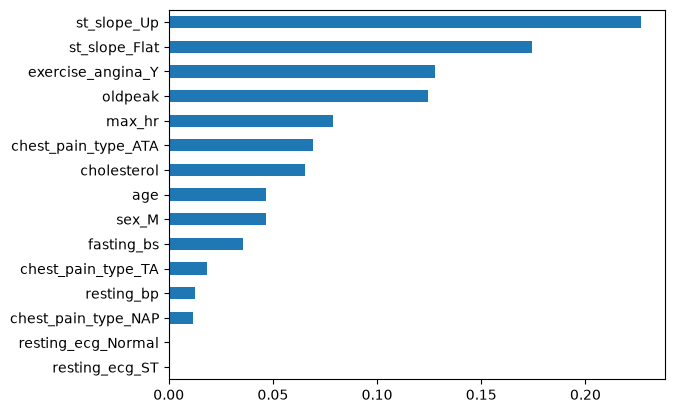

In [20]:
X = pd.get_dummies(df.drop(columns="heart_disease"), drop_first=True).astype(float)
X = X.fillna(X.median())          # only for this EDA step
mi = pd.Series(
    mutual_info_classif(X, df["heart_disease"], random_state=42),
    index=X.columns,
).sort_values(ascending=False)
print(mi.round(3))
mi.plot(kind="barh")
plt.gca().invert_yaxis()
plt.show()

- Most informative: st_slope (Up 0.227, Flat 0.175), exercise_angina_Y (0.128), oldpeak (0.125), max_hr (0.079).
- Least informative: resting_ecg (0.000), resting_bp (0.012).

### Data preparation

In [21]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

(len(df_full_train), len(df_train), len(df_val), len(df_test))

(734, 550, 184, 184)

In [22]:
y_train = df_train.heart_disease.values
y_val = df_val.heart_disease.values
y_test = df_test.heart_disease.values

In [23]:
df_train.head()

,age,sex,chest_pain_type,resting_bp,cholesterol,fasting_bs,resting_ecg,max_hr,exercise_angina,oldpeak,st_slope,heart_disease
795,42,M,NAP,120.0,240.0,1,Normal,194,N,0.8,Down,0
322,38,F,ASY,105.0,NaN,1,Normal,166,N,2.8,Up,1
686,57,F,ASY,120.0,354.0,0,Normal,163,Y,0.6,Up,0
440,52,M,NAP,128.0,NaN,0,ST,180,N,3.0,Up,1
7,54,M,ATA,110.0,208.0,0,Normal,142,N,0.0,Up,0


In [24]:
del df_train["heart_disease"]
del df_val["heart_disease"]
del df_test["heart_disease"]

In [25]:
df_train.head()

,age,sex,chest_pain_type,resting_bp,cholesterol,fasting_bs,resting_ecg,max_hr,exercise_angina,oldpeak,st_slope
795,42,M,NAP,120.0,240.0,1,Normal,194,N,0.8,Down
322,38,F,ASY,105.0,NaN,1,Normal,166,N,2.8,Up
686,57,F,ASY,120.0,354.0,0,Normal,163,Y,0.6,Up
440,52,M,NAP,128.0,NaN,0,ST,180,N,3.0,Up
7,54,M,ATA,110.0,208.0,0,Normal,142,N,0.0,Up


### Modeling 

In [26]:
features = numerical_col + categorical_col
fill_cols = ["resting_bp", "cholesterol"]

In [27]:
def train(df, y, model):
    medians = df[fill_cols].median()                      # learned from training rows only
    dicts = df[features].fillna(medians).to_dict(orient="records")
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(dicts)
    model.fit(X, y)
    return medians, dv, model

In [ ]:
def predict(df, medians, dv, model):
    dicts = df[features].fillna(medians).to_dict(orient="records")
    X = dv.transform(dicts)
    return model.predict_proba(X)[:, 1]

In [29]:
def evaluate(y, proba, threshold=0.5):
    pred = proba >= threshold
    return {"accuracy": accuracy_score(y, pred), "auc": roc_auc_score(y, proba),
            "recall": recall_score(y, pred), "precision": precision_score(y, pred)}

`train` fills missing cholesterol and resting BP with the median of the training rows, one-hot encodes the categorical features with `DictVectorizer` and fits the model. `predict` applies the same steps to new data and returns the probability of heart disease. `evaluate` returns accuracy, AUC, recall and precision for a given threshold (default 0.5).

In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [31]:
candidates = {
    "logistic_regression": LogisticRegression(solver="liblinear", max_iter=1000),
    "decision_tree": DecisionTreeClassifier(random_state=1),
    "random_forest": RandomForestClassifier(random_state=1, n_jobs=-1),
}
rows = []
for name, model in candidates.items():
    med, dv_, m = train(df_train, y_train, model)
    rows.append({"model": name, **evaluate(y_val, predict(df_val, med, dv_, m))})
pd.DataFrame(rows).round(3).sort_values("auc", ascending=False)

,model,accuracy,auc,recall,precision
0,logistic_regression,0.826,0.903,0.837,0.837
2,random_forest,0.842,0.901,0.888,0.829
1,decision_tree,0.739,0.736,0.786,0.740


With default settings, logistic regression (AUC 0.903) and random forest (0.901) are about equal. The decision tree is much weaker (0.736) because an unrestricted tree memorizes the training data. Next I tune each model.

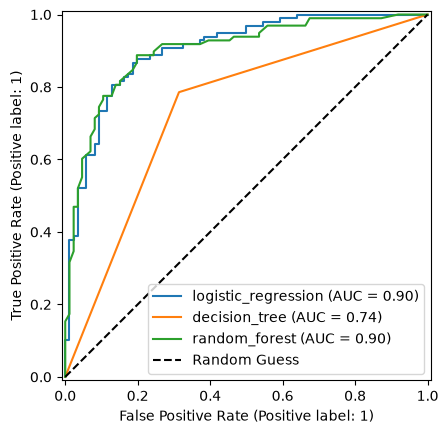

In [33]:
from sklearn.metrics import RocCurveDisplay

ax = plt.gca()
for name, model in candidates.items():
  med, dv_, m = train(df_train, y_train, model)
  y_pred_proba = predict(df_val, med, dv_, m)

  RocCurveDisplay.from_predictions(y_val, y_pred_proba, name=name, ax=ax)

plt.plot([0, 1], [0, 1], "k--", label="Random Guess")
plt.legend()
plt.show()

The logistic regression and random forest curves are close together and well above the random-guess line, the decision tree is clearly lower. This matches the AUC values.

#### Tuning model

Logistic regression: with different C

In [34]:
for C in [0.01, 0.1, 1, 10]:
    med, dv_, m = train(df_train, y_train, LogisticRegression(solver="liblinear", C=C, max_iter=1000))
    print("C", C, round(roc_auc_score(y_val, predict(df_val, med, dv_, m)), 3))


C 0.01 0.872
C 0.1 0.901
C 1 0.903
C 10 0.904


**Logistic regression (C):** AUC rises from 0.872 at C=0.01 (too restricted) to 0.903 at C=1, then stays flat at C=10 (0.904). I choose C=1, the simplest setting on the plateau.

Decision tree: with different depths

In [ ]:
for depth in [2, 3, 4, 5, 6, 8]:
    m = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=10, random_state=1)
    med, dv_, m = train(df_train, y_train, m)
    print("depth", depth, round(roc_auc_score(y_val, predict(df_val, med, dv_, m)), 3))

depth 2 0.822
depth 3 0.853
depth 4 0.852
depth 5 0.862
depth 6 0.862
depth 8 0.845


**Decision tree (max_depth):** AUC improves from 0.822 at depth 2 to 0.862 at depths 5–6, then falls to 0.845 at depth 8, a sign of overfitting. I choose max_depth=5.

Random forest: with different depths and tree counts

In [37]:
for depth in [4, 6, 10]:
    for n in [50, 100, 200]:
        m = RandomForestClassifier(n_estimators=n, max_depth=depth, min_samples_leaf=3,
                                   random_state=1, n_jobs=-1)
        med, dv_, m = train(df_train, y_train, m)
        print("depth", depth, "trees", n, round(roc_auc_score(y_val, predict(df_val, med, dv_, m)), 3))

depth 4 trees 50 0.892
depth 4 trees 100 0.896
depth 4 trees 200 0.894
depth 6 trees 50 0.903
depth 6 trees 100 0.901
depth 6 trees 200 0.902
depth 10 trees 50 0.902
depth 10 trees 100 0.905
depth 10 trees 200 0.903


**Random forest (max_depth, n_estimators):** Deeper trees help a little (about 0.89 at depth 4, 0.90 at depth 6 and 10). More than 100 trees makes almost no difference. Best: depth 10 with 100 trees (0.905), depth 6 is nearly as good (0.901).

**Model selection:**

| Model | Best settings | Validation AUC |
|---|---|---|
| Logistic regression | C=1 | 0.903 |
| Decision tree | max_depth=5, min_samples_leaf=10 | 0.862 |
| Random forest | max_depth=10, n_estimators=100, min_samples_leaf=3 | 0.905 |

Logistic regression and random forest perform almost the same; the 0.002 difference is within noise on about 184 validation patients. I choose logistic regression because it is simpler and gives a smaller model file. The decision tree is clearly weaker.

#### Final training with df_full_train dataset

In [40]:
y_full_train = df_full_train.heart_disease.values
del df_full_train["heart_disease"]

In [42]:
# Final model: logistic regression with the best C, trained on train + validation data
final_model = LogisticRegression(solver="liblinear", C=1, max_iter=1000)
med, dv_, final = train(df_full_train, y_full_train, final_model)

# Test set
proba_test = predict(df_test, med, dv_, final)
scores = evaluate(y_test, proba_test)
print({k: round(v, 3) for k, v in scores.items()})

print(confusion_matrix(y_test, proba_test >= 0.5))

{'accuracy': 0.924, 'auc': 0.954, 'recall': 0.945, 'precision': 0.929}
[[ 66   8]
 [  6 104]]


In [65]:
med_t, dv_t, m_t = train(df_train, y_train, LogisticRegression(solver="liblinear", C=1, max_iter=1000))
proba_val = predict(df_val, med_t, dv_t, m_t)

rows = []
for t in np.arange(0.2, 0.81, 0.05):
    r = evaluate(y_val, proba_val, threshold=t)
    rows.append({"threshold": round(t, 2), "recall": r["recall"],
                 "precision": r["precision"], "accuracy": r["accuracy"]})
pd.DataFrame(rows).round(3)

,threshold,recall,precision,accuracy
0,0.20,0.939,0.719,0.772
1,0.25,0.918,0.744,0.788
2,0.30,0.918,0.763,0.804
3,0.35,0.908,0.788,0.821
4,0.40,0.878,0.811,0.826
5,0.45,0.867,0.833,0.837
6,0.50,0.837,0.837,0.826
7,0.55,0.816,0.860,0.832
8,0.60,0.796,0.876,0.832
9,0.65,0.755,0.881,0.815


Lowering the threshold from 0.5 to 0.35 raises validation recall from 0.837 to 0.908 and lowers precision from 0.837 to 0.788, while accuracy stays about the same (0.826 to 0.821). Below 0.35 recall barely improves (0.918 at 0.30) while precision keeps falling. Because missing a sick patient is worse than a false alarm, I use 0.35 in the service.

In [66]:
print({k: round(v, 3) for k, v in evaluate(y_test, proba_test, threshold=0.35).items()})
print(confusion_matrix(y_test, proba_test >= 0.35))

{'accuracy': 0.908, 'auc': 0.954, 'recall': 0.955, 'precision': 0.897}
[[ 62  12]
 [  5 105]]


At threshold 0.35 (the one used in the service) the test set gives accuracy 0.908, recall 0.955 and precision 0.897: the model finds 105 of 110 sick patients and raises 12 false alarms. Compared with threshold 0.5 (104 found, 8 false alarms), it catches 1 more sick patient at the cost of 4 more false alarms. On 184 patients this difference is small, so the test set neither strongly supports nor contradicts the choice I made on the validation set.

### Saving the model

In [43]:
import pickle
with open("model.bin", "wb") as f:
    pickle.dump((med, dv_, final), f)

### Loading the model and predicting 

In [44]:
with open("model.bin", "rb") as f:
    med, dv_, final = pickle.load(f)

In [91]:
df_test.iloc[[5]]

,age,sex,chest_pain_type,resting_bp,cholesterol,fasting_bs,resting_ecg,max_hr,exercise_angina,oldpeak,st_slope
191,50,M,ATA,170.0,209.0,0,ST,116,N,0.0,Up


In [92]:
df.iloc[[191]]

,age,sex,chest_pain_type,resting_bp,cholesterol,fasting_bs,resting_ecg,max_hr,exercise_angina,oldpeak,st_slope,heart_disease
191,50,M,ATA,170.0,209.0,0,ST,116,N,0.0,Up,0


In [100]:
new_test = df_test.iloc[5].fillna(med).to_dict()
new_test

{'age': 50,
 'sex': 'M',
 'chest_pain_type': 'ATA',
 'resting_bp': 170.0,
 'cholesterol': 209.0,
 'fasting_bs': 0,
 'resting_ecg': 'ST',
 'max_hr': 116,
 'exercise_angina': 'N',
 'oldpeak': 0.0,
 'st_slope': 'Up'}

In [101]:
dv_.transform(new_test)

array([[ 50.,   0.,   1.,   0.,   0., 209.,   1.,   0.,   0., 116.,   0.,
        170.,   0.,   0.,   1.,   0.,   1.,   0.,   0.,   1.]])

In [102]:
final.predict_proba(dv_.transform(new_test))[:,1].round(2)

array([0.09])

Sanity check: the saved model is loaded and used on one patient. The predicted probability is 0.09, below 0.35, so the model says "not disease" and this patient also has no heart disease. So it's predicting correct.